In [1]:
!git clone https://github.com/WollyMonjac/Tiny-2.1.git
%cd /content/Tiny-2.1/training

fatal: destination path 'Tiny-2.1' already exists and is not an empty directory.
/content/Tiny-2.1/training


In [2]:
import math, os, random, struct
import numpy as np
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import train2

def load_v2_bin(path):
    """Load a version-2 ('TNY2') 8-bit weight file into train2.Model."""
    b = open(path, "rb").read()
    assert b[:4] == b"TNY2", "Expected a TNY2 weight file"
    D, L, H, HID = struct.unpack_from("<4h", b, 4)
    off = [12]

    def table(r, c):
        w = np.empty((r, c), dtype=np.float32)
        for i in range(r):
            s = struct.unpack_from("<f", b, off[0])[0]
            w[i] = np.frombuffer(b, np.int8, c, off[0] + 4).astype(np.float32) * s
            off[0] += 4 + c
        return torch.tensor(w)

    def gains():
        g = np.frombuffer(b, "<f4", D, off[0]).copy()
        off[0] += 4 * D
        return torch.tensor(g)

    m = train2.Model(train2.Cfg(D, L, H, HID))
    with torch.no_grad():
        m.emb.weight.copy_(table(train2.VOCAB, D))
        m.pos.weight.copy_(table(train2.CTX, D))
        for blk in m.blocks:
            blk.n1.g.copy_(gains())
            for lin in (blk.q, blk.k, blk.v, blk.o):
                lin.weight.copy_(table(D, D))
            blk.n2.g.copy_(gains())
            blk.f1.weight.copy_(table(HID, D))
            blk.f2.weight.copy_(table(D, HID))
        m.nf.g.copy_(gains())
    assert off[0] == len(b), "size mismatch"
    return m

model = load_v2_bin("/content/Tiny-2.1/dos/TINY.BIN")
model.eval()
print("Loaded:", model.c, "| Parameters:", f"{sum(p.numel() for p in model.parameters()):,}")

Loaded: D=96 L=4 H=4 HID=256 | Parameters: 366,528


In [3]:
x_small = torch.tensor([1.0, 7.0])
g_small = torch.tensor([1.0, 2.0])  # learned per-feature scale (gain)

# 1. Compute Root Mean Square: sqrt(mean(x^2) + eps)
eps = 1e-5
rms_small = torch.sqrt(torch.mean(x_small ** 2) + eps)

# 2. Divide by RMS, then multiply by gain g
normed_small = x_small / rms_small
out_small = normed_small * g_small

# 3. Repeat with a 10x larger input vector [10.0, 70.0]
x_loud = 10.0 * x_small
rms_loud = torch.sqrt(torch.mean(x_loud ** 2) + eps)
normed_loud = x_loud / rms_loud

print("x_small RMS :", round(rms_small.item(), 4), "| normed:", np.round(normed_small.numpy(), 4))
print("x_loud  RMS :", round(rms_loud.item(), 4),  "| normed:", np.round(normed_loud.numpy(), 4))
print("Difference due to eps:", (normed_small - normed_loud).abs().max().item())
print("Final output after gain g:", np.round(out_small.numpy(), 4))

x_small RMS : 5.0 | normed: [0.2 1.4]
x_loud  RMS : 50.0 | normed: [0.2 1.4]
Difference due to eps: 2.384185791015625e-07
Final output after gain g: [0.2 2.8]


In [4]:
ids = torch.tensor([train2.encode("2+2?\n")], dtype=torch.long)  # shape: (1, 5)
T = ids.shape[1]

with torch.no_grad():
    x_in = model.emb(ids) + model.pos(torch.arange(T))           # shape: (1, 5, 96)
    blk = model.blocks[0]
    h1 = blk.n1(x_in)                                            # shape: (1, 5, 96)

    # Direct calculation of normalized vector before multiplying by gain g
    x_in_normed_direct = x_in * torch.rsqrt(x_in.pow(2).mean(dim=-1, keepdim=True) + 1e-5)
    rms_before = x_in.pow(2).mean(dim=-1).sqrt()
    rms_normed = x_in_normed_direct.pow(2).mean(dim=-1).sqrt()
    rms_final  = h1.pow(2).mean(dim=-1).sqrt()

print("RMS of each token BEFORE n1        :", np.round(rms_before[0].numpy(), 4))
print("RMS of direct normalized vector    :", np.round(rms_normed[0].numpy(), 4))
print("RMS of final output h1 (after gain):", np.round(rms_final[0].numpy(), 4))
print("First 6 learned gains blk.n1.g     :", np.round(blk.n1.g[:6].detach().numpy(), 3))

RMS of each token BEFORE n1        : [0.5005 0.2641 0.2997 0.3375 0.2773]
RMS of direct normalized vector    : [1.     0.9999 0.9999 1.     0.9999]
RMS of final output h1 (after gain): [0.3575 0.3759 0.356  0.3244 0.3457]
First 6 learned gains blk.n1.g     : [0.322 0.409 0.651 0.373 0.279 0.283]


In [5]:
with torch.no_grad():
    out_normal = blk.n1(x_in)
    out_scaled = blk.n1(50.0 * x_in)
    diff = (out_normal - out_scaled).abs().max().item()

print("Max absolute difference after 50x scaling:", diff)

Max absolute difference after 50x scaling: 0.00011301040649414062


In [6]:
signal_plain = 1.0
signal_resid = 1.0
deltas = [0.05, -0.02, 0.08, 0.04]

print("Signal value across 4 layers:")
for layer_idx, d in enumerate(deltas):
    signal_plain = signal_plain * 0.5          # without shortcut (multiplicative decay)
    signal_resid = signal_resid + d            # with residual shortcut (additive refinement)
    print(f"  After Layer {layer_idx}: plain = {signal_plain:.4f} | residual = {signal_resid:.4f}")

Signal value across 4 layers:
  After Layer 0: plain = 0.5000 | residual = 1.0500
  After Layer 1: plain = 0.2500 | residual = 1.0300
  After Layer 2: plain = 0.1250 | residual = 1.1100
  After Layer 3: plain = 0.0625 | residual = 1.1500


In [7]:
with torch.no_grad():
    sp = lambda t: t.view(1, T, 4, 24).transpose(1, 2)
    a = F.scaled_dot_product_attention(sp(blk.q(h1)), sp(blk.k(h1)), sp(blk.v(h1)), is_causal=True)
    attn_out = blk.o(a.transpose(1, 2).reshape(1, T, 96))

    # Additive residual connection
    x_mid = x_in + attn_out

print("x_in shape    :", tuple(x_in.shape))
print("attn_out shape:", tuple(attn_out.shape))
print("x_mid shape   :", tuple(x_mid.shape))
print("Mean vector norm — x_in:", round(x_in.norm(dim=-1).mean().item(), 3),
      "| attn_out:", round(attn_out.norm(dim=-1).mean().item(), 3),
      "| x_mid:", round(x_mid.norm(dim=-1).mean().item(), 3))

x_in shape    : (1, 5, 96)
attn_out shape: (1, 5, 96)
x_mid shape   : (1, 5, 96)
Mean vector norm — x_in: 3.29 | attn_out: 4.999 | x_mid: 5.771


In [8]:
h_tiny = torch.tensor([1.0, -1.0])

W1_tiny = torch.tensor([
    [ 1.5, -0.5],  # neuron 0 -> 1.0*(1.5)  + (-1.0)*(-0.5) =  2.0
    [-1.0,  2.0],  # neuron 1 -> 1.0*(-1.0) + (-1.0)*(2.0)  = -3.0
    [ 0.5,  0.0],  # neuron 2 -> 1.0*(0.5)  + (-1.0)*(0.0)  =  0.5
    [-0.5,  0.5],  # neuron 3 -> 1.0*(-0.5) + (-1.0)*(0.5)  = -1.0
])

W2_tiny = torch.tensor([
    [ 0.3, 0.5, 0.4, -0.2],
    [-0.2, 0.1, 0.0,  0.6],
])

pre_relu = h_tiny @ W1_tiny.T
post_relu = F.relu(pre_relu)
mlp_out_tiny = post_relu @ W2_tiny.T

print("1. Pre-ReLU (4 neurons)  :", pre_relu.numpy())
print("2. Post-ReLU (negatives=0):", post_relu.numpy())
print("3. Final 2D MLP output    :", np.round(mlp_out_tiny.numpy(), 3))

1. Pre-ReLU (4 neurons)  : [ 2.  -3.   0.5 -1. ]
2. Post-ReLU (negatives=0): [2.  0.  0.5 0. ]
3. Final 2D MLP output    : [ 0.8 -0.4]


In [9]:
with torch.no_grad():
    h2 = blk.n2(x_mid)
    mlp_hidden = F.relu(blk.f1(h2))     # shape: (1, 5, 256)
    mlp_out = blk.f2(mlp_hidden)        # shape: (1, 5, 96)
    x_out_manual = x_mid + mlp_out      # second residual connection

    x_out_block = blk(x_in)             # direct Block forward call

print("mlp_hidden shape:", tuple(mlp_hidden.shape))
print("x_out_manual shape:", tuple(x_out_manual.shape))
print("Max absolute difference vs blk(x_in):", (x_out_manual - x_out_block).abs().max().item())

active_pct = 100.0 * (mlp_hidden[0, -1] > 0).float().mean().item()
print(f"Active ReLU units at position -1: {active_pct:.1f}% ({int((mlp_hidden[0, -1] > 0).sum())}/256)")

mlp_hidden shape: (1, 5, 256)
x_out_manual shape: (1, 5, 96)
Max absolute difference vs blk(x_in): 0.0
Active ReLU units at position -1: 12.5% (32/256)


Emb + Pos      :  21,600 (5.9%)
Attention (4L) : 147,456 (40.2%)
MLP (4L)       : 196,608 (53.6%)
RMSNorm (g)    :     864 (0.2%)


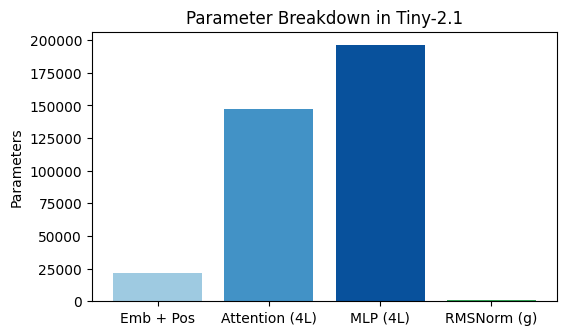

In [10]:
emb_p  = model.emb.weight.numel() + model.pos.weight.numel()
attn_p = sum(getattr(b, n).weight.numel() for b in model.blocks for n in ("q", "k", "v", "o"))
mlp_p  = sum(getattr(b, n).weight.numel() for b in model.blocks for n in ("f1", "f2"))
norm_p = sum(p.numel() for p in model.parameters() if p.dim() == 1)

names  = ["Emb + Pos", "Attention (4L)", "MLP (4L)", "RMSNorm (g)"]
counts = [emb_p, attn_p, mlp_p, norm_p]
for name, cnt in zip(names, counts):
    print(f"{name:15s}: {cnt:7,} ({100*cnt/sum(counts):.1f}%)")

plt.figure(figsize=(6, 3.5))
plt.bar(names, counts, color=["#9ecae1", "#4292c6", "#08519c", "#31a354"])
plt.ylabel("Parameters")
plt.title("Parameter Breakdown in Tiny-2.1")
plt.show()

In [11]:
emb_3 = torch.tensor([
    [0.1,  0.9],  # candidate 0: '2'
    [0.9,  0.7],  # candidate 1: '4'
    [0.0, -0.5],  # candidate 2: '\n'
])
chars_3 = ["'2'", "'4'", "'\\n'"]

h_final_small = torch.tensor([0.8, 0.6])  # final normalized output vector

# Logits = h @ emb^T
logits_3 = h_final_small @ emb_3.T
probs_3 = F.softmax(logits_3, dim=0)

for ch, sc, pr in zip(chars_3, logits_3.tolist(), probs_3.tolist()):
    print(f"  {ch:>4}: logit = {sc:+.3f} -> prob = {pr:.3f}")

   '2': logit = +0.620 -> prob = 0.325
   '4': logit = +1.140 -> prob = 0.546
  '\n': logit = -0.300 -> prob = 0.129


In [12]:
q_prompt = "what is 2+2?\n"
p_ids = torch.tensor([train2.encode(q_prompt)], dtype=torch.long)

with torch.no_grad():
    x = model.emb(p_ids) + model.pos(torch.arange(p_ids.shape[1]))
    for blk_idx, blk in enumerate(model.blocks):
        x = blk(x)
        print(f"After Block {blk_idx}: shape={tuple(x.shape)}, mean norm={x.norm(dim=-1).mean():.3f}")

    x_final = model.nf(x)                               # (1, T, 96)
    logits_manual = x_final @ model.emb.weight.t()      # (1, T, 97)
    logits_direct = model(p_ids)                        # Model.forward()

    print("Max diff vs model(p_ids):", (logits_manual - logits_direct).abs().max().item())

    # Check top-5 predicted characters for the last token position
    probs_next = F.softmax(logits_manual[0, -1], dim=-1)
    top5_p, top5_id = torch.topk(probs_next, 5)

print(f"\nTop-5 next characters after {repr(q_prompt)}:")
for p_val, tok_id in zip(top5_p.tolist(), top5_id.tolist()):
    ch_str = repr(train2.decode([tok_id]))[1:-1] if tok_id > 0 else "<pad>"
    print(f"  {ch_str:>4} (ID {tok_id:2d}): prob = {p_val:.4f}")

After Block 0: shape=(1, 13, 96), mean norm=24.280
After Block 1: shape=(1, 13, 96), mean norm=38.204
After Block 2: shape=(1, 13, 96), mean norm=42.393
After Block 3: shape=(1, 13, 96), mean norm=54.258
Max diff vs model(p_ids): 0.0

Top-5 next characters after 'what is 2+2?\n':
     T (ID 54): prob = 0.3571
     I (ID 43): prob = 0.2442
     2 (ID 20): prob = 0.1587
     4 (ID 22): prob = 0.1105
     1 (ID 19): prob = 0.0826


In [13]:
@torch.no_grad()
def top5_next(prompt_str):
    ids = torch.tensor([train2.encode(prompt_str)], dtype=torch.long)
    probs = F.softmax(model(ids)[0, -1], dim=-1)
    vals, idxs = torch.topk(probs, 5)
    print(f"\nPrompt: {repr(prompt_str)}")
    for v, i in zip(vals.tolist(), idxs.tolist()):
        ch = repr(train2.decode([i]))[1:-1] if i > 0 else "<pad>"
        print(f"  {ch:>4} (ID {i:2d}): {v:.4f}")

top5_next("what is the capital of ")
top5_next("what is the capital of france?\n")


Prompt: 'what is the capital of '
     E (ID 39): 0.3522
     I (ID 43): 0.2740
     W (ID 57): 0.1317
     w (ID 89): 0.0622
     A (ID 35): 0.0354

Prompt: 'what is the capital of france?\n'
     T (ID 54): 0.3514
     P (ID 50): 0.3318
     I (ID 43): 0.2820
     F (ID 40): 0.0182
     K (ID 45): 0.0051


In [14]:
prompt = "what is the capital of france?\n"
x = torch.tensor([train2.encode(prompt)], dtype=torch.long)
generated_ids = []

print(f"Starting prompt: {repr(prompt)}")
with torch.no_grad():
    for step in range(35):
        logits = model(x)[:, -1, :]              # (1, 97) at the last token
        probs = F.softmax(logits, dim=-1)
        nxt = int(logits.argmax(dim=-1).item())  # greedy decoding
        conf = float(probs[0, nxt].item())
        ch_str = repr(train2.decode([nxt]))[1:-1]
        print(f"  step {step+1:2d}: char={ch_str:>4} (ID={nxt:2d}, prob={conf:.3f})")

        if nxt <= 1:  # stop on newline (ID 1) or pad (ID 0)
            break
        generated_ids.append(nxt)
        x = torch.cat([x, torch.tensor([[nxt]], dtype=torch.long)], dim=1)

print("Final generated answer:", train2.decode(generated_ids))

Starting prompt: 'what is the capital of france?\n'
  step  1: char=   T (ID=54, prob=0.351)
  step  2: char=   h (ID=74, prob=1.000)
  step  3: char=   e (ID=71, prob=1.000)
  step  4: char=     (ID= 2, prob=1.000)
  step  5: char=   c (ID=69, prob=1.000)
  step  6: char=   a (ID=67, prob=1.000)
  step  7: char=   p (ID=82, prob=1.000)
  step  8: char=   i (ID=75, prob=1.000)
  step  9: char=   t (ID=86, prob=1.000)
  step 10: char=   a (ID=67, prob=1.000)
  step 11: char=   l (ID=78, prob=1.000)
  step 12: char=     (ID= 2, prob=1.000)
  step 13: char=   o (ID=81, prob=0.571)
  step 14: char=   f (ID=72, prob=1.000)
  step 15: char=     (ID= 2, prob=1.000)
  step 16: char=   F (ID=40, prob=0.999)
  step 17: char=   r (ID=84, prob=1.000)
  step 18: char=   a (ID=67, prob=1.000)
  step 19: char=   n (ID=80, prob=1.000)
  step 20: char=   c (ID=69, prob=1.000)
  step 21: char=   e (ID=71, prob=0.999)
  step 22: char=     (ID= 2, prob=1.000)
  step 23: char=   i (ID=75, prob=1.000)
  ste

In [15]:
@torch.no_grad()
def generate_from(prompt_str, max_steps=40):
    x = torch.tensor([train2.encode(prompt_str)], dtype=torch.long)
    out = []
    for _ in range(max_steps):
        nxt = int(model(x)[:, -1, :].argmax(dim=-1).item())
        if nxt <= 1:
            break
        out.append(nxt)
        x = torch.cat([x, torch.tensor([[nxt]], dtype=torch.long)], dim=1)
    return train2.decode(out)

print("Standard prompt continuation :", generate_from("is paris in germany?\n"))
print("Forced 'Yes, ' continuation  :", "Yes, " + generate_from("is paris in germany?\nYes, "))

Standard prompt continuation : Yes, Paris is in Asia.
Forced 'Yes, ' continuation  : Yes, Paris is in Asia.


In [16]:
row_float = torch.tensor([0.0, 0.5, -1.0, 0.25])

# 1. Scale factor s = max(|row|) / 127
s = max(float(row_float.abs().max()), 1e-8) / 127.0

# 2. Quantize to signed 8-bit integers [-127, 127]
row_int8 = torch.clamp(torch.round(row_float / s), -127, 127).to(torch.int8)

# 3. Dequantize to inspect reconstruction error
row_restored = row_int8.float() * s
abs_error = (row_float - row_restored).abs()

print("Original float32:", row_float.numpy())
print("Scale factor s  :", round(s, 6))
print("Stored int8     :", row_int8.numpy())
print("Restored float  :", np.round(row_restored.numpy(), 4))
print("Absolute error  :", np.round(abs_error.numpy(), 4))

Original float32: [ 0.    0.5  -1.    0.25]
Scale factor s  : 0.007874
Stored int8     : [   0   64 -127   32]
Restored float  : [ 0.      0.5039 -1.      0.252 ]
Absolute error  : [0.     0.0039 0.     0.002 ]


In [17]:
# 1. Compare initial loss against theoretical uniform-prediction baseline
train2._POOL.clear()
rng = random.Random(0)
fresh = train2.Model(train2.Cfg())
opt = torch.optim.AdamW(fresh.parameters(), lr=2e-3, weight_decay=0.01)

xb, mb = train2.batch(rng, 32)
initial_loss = train2.loss_fn(fresh, xb, mb).item()
uniform_baseline = math.log(97)

print(f"Theoretical uniform baseline ln(97): {uniform_baseline:.3f}")
print(f"Actual empirical initial loss       : {initial_loss:.3f}")

# 2. Run 60 optimization steps on fresh model
losses = [initial_loss]
for _ in range(60):
    xb, mb = train2.batch(rng, 32)
    loss = train2.loss_fn(fresh, xb, mb)
    opt.zero_grad()
    loss.backward()
    torch.nn.utils.clip_grad_norm_(fresh.parameters(), 1.0)
    opt.step()
    losses.append(loss.item())

print(f"Loss after 60 training steps       : {losses[-1]:.3f}")

# 3. Export model to compare file footprints
train2.save_model(model, "check_float.pt")
bin_size = train2.export(model, "check_int8.bin")
pt_size = os.path.getsize("check_float.pt")
print(f"Float32 .pt: {pt_size:,} bytes | Int8 .bin: {bin_size:,} bytes ({pt_size/bin_size:.2f}x smaller)")

Theoretical uniform baseline ln(97): 4.575
Actual empirical initial loss       : 4.817
Loss after 60 training steps       : 2.568
Float32 .pt: 1,478,494 bytes | Int8 .bin: 381,808 bytes (3.87x smaller)


In [18]:
fresh_q = train2.quantized_copy(fresh)
fresh.eval()
fresh_q.eval()

print("Measuring genuine float32 -> int8 quantization error on newly trained model:")
max_errors = []
with torch.no_grad():
    for (name, p_fp), (_, p_q) in zip(fresh.named_parameters(), fresh_q.named_parameters()):
        if p_fp.dim() == 2:
            err = (p_fp - p_q).abs().max().item()
            max_errors.append(err)
            print(f"  {name:22s}: max error = {err:.6f}")

print(f"\nOverall peak quantization error across all 2D layers: {max(max_errors):.6f}")

# Re-quantization check on published model (verifying round-trip stability)
model_requant = train2.quantized_copy(model)
model_requant.eval()
test_qs = ["what is 2+2?", "what is the capital of france?"]
print("\nPublished model output (restored int8)    :", train2.answer_many(model, test_qs))
print("Published model output (after requantize) :", train2.answer_many(model_requant, test_qs))

Measuring genuine float32 -> int8 quantization error on newly trained model:
  emb.weight            : max error = 0.000915
  pos.weight            : max error = 0.000805
  blocks.0.q.weight     : max error = 0.000796
  blocks.0.k.weight     : max error = 0.000815
  blocks.0.v.weight     : max error = 0.000774
  blocks.0.o.weight     : max error = 0.000740
  blocks.0.f1.weight    : max error = 0.000972
  blocks.0.f2.weight    : max error = 0.000651
  blocks.1.q.weight     : max error = 0.000907
  blocks.1.k.weight     : max error = 0.000939
  blocks.1.v.weight     : max error = 0.000863
  blocks.1.o.weight     : max error = 0.000782
  blocks.1.f1.weight    : max error = 0.000972
  blocks.1.f2.weight    : max error = 0.000577
  blocks.2.q.weight     : max error = 0.000753
  blocks.2.k.weight     : max error = 0.000786
  blocks.2.v.weight     : max error = 0.000790
  blocks.2.o.weight     : max error = 0.000804
  blocks.2.f1.weight    : max error = 0.000831
  blocks.2.f2.weight    : max 